# EDA of URL Phishing Dataset
Exploratory Data Analysis on the malicious URL dataset to understand class distribution, URL characteristics, and feature patterns before model training.

In [1]:
# Cell 1 — Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import warnings
warnings.filterwarnings('ignore')

print("All imports successful!")

All imports successful!


## Load Dataset

In [2]:
# Cell 2 — Load Dataset
df = pd.read_csv('malicious_phish.csv')
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
df.head()

Shape: (651191, 2)

Columns: ['url', 'type']

First 5 rows:


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


## Class Distribution
We analyze the distribution of URL types in the dataset.

Type counts:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Percentages:
type
benign        65.741541
defacement    14.812398
phishing      14.452135
malware        4.993927
Name: proportion, dtype: float64


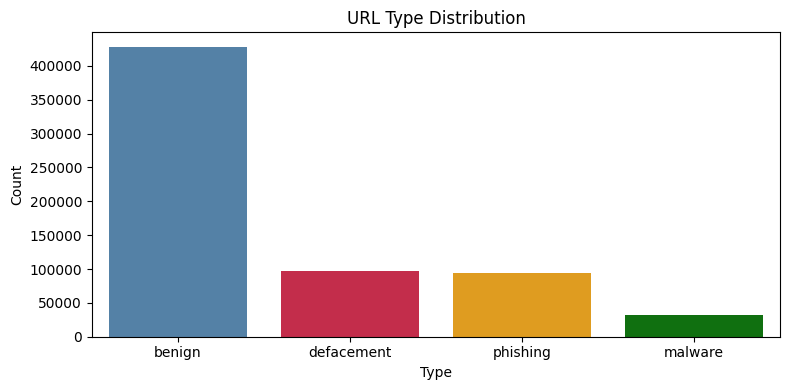

In [3]:
# Cell 3 — Class Distribution
print("Type counts:")
print(df['type'].value_counts())
print("\nPercentages:")
print(df['type'].value_counts(normalize=True) * 100)

plt.figure(figsize=(8,4))
sns.countplot(x='type', data=df, palette=['steelblue','crimson','orange','green'],
              order=df['type'].value_counts().index)
plt.title('URL Type Distribution')
plt.ylabel('Count')
plt.xlabel('Type')
plt.tight_layout()
plt.show()

## URL Length Analysis
We analyze URL length as it is a key lexical feature malicious URLs tend to be longer than benign ones.

Average URL length by type:
type
benign        57.7
defacement    86.3
malware       56.5
phishing      45.9
Name: url_length, dtype: float64


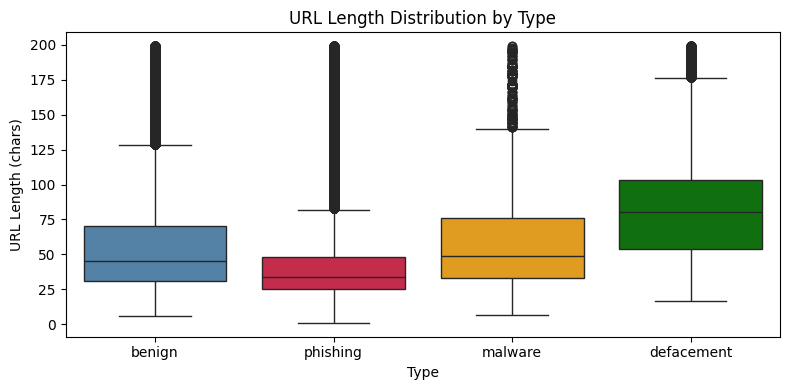

In [5]:
# Cell 4 — URL Length Analysis
df['url_length'] = df['url'].str.len()

print("Average URL length by type:")
print(df.groupby('type')['url_length'].mean().round(1))

plt.figure(figsize=(8,4))
sns.boxplot(x='type', y='url_length', data=df[df['url_length'] < 200], 
            palette=['steelblue','crimson','orange','green'],
            order=['benign','phishing','malware','defacement'])
plt.title('URL Length Distribution by Type')
plt.xlabel('Type')
plt.ylabel('URL Length (chars)')
plt.tight_layout()
plt.show()

### URL length alone isn't enough to detect phishing, which justifies using multiple lexical features combined!

## Suspicious Keyword Analysis
We analyze the presence of suspicious keywords commonly found in phishing URLs such as "login", "verify", "secure", "account", and "update".

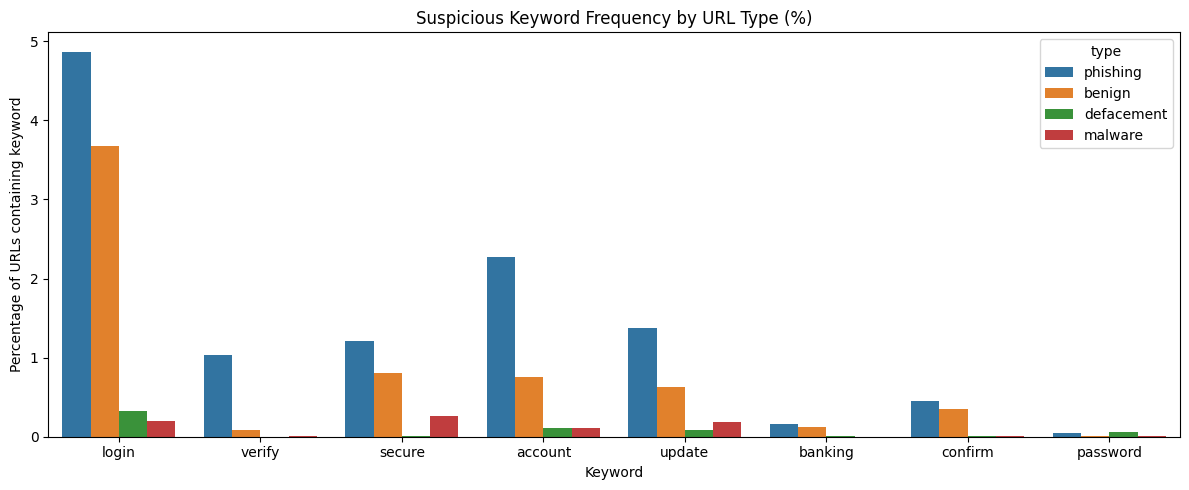

In [6]:
# Cell 5 — Suspicious Keywords
keywords = ['login', 'verify', 'secure', 'account', 'update', 'banking', 'confirm', 'password']

results = []
for kw in keywords:
    for t in df['type'].unique():
        subset = df[df['type']==t]
        count = subset['url'].str.contains(kw, case=False).sum()
        pct = count / len(subset) * 100
        results.append({'keyword': kw, 'type': t, 'percentage': pct})

kw_df = pd.DataFrame(results)

plt.figure(figsize=(12,5))
sns.barplot(x='keyword', y='percentage', hue='type', data=kw_df)
plt.title('Suspicious Keyword Frequency by URL Type (%)')
plt.ylabel('Percentage of URLs containing keyword')
plt.xlabel('Keyword')
plt.tight_layout()
plt.show()

## Missing Values Check
We verify data completeness before feature extraction and model training.

In [7]:
# Cell 6 — Missing Values
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")
print(f"Total rows: {len(df)}")

Missing values per column:
url           0
type          0
url_length    0
dtype: int64

Total missing: 0
Total rows: 651191


## HTTPS Presence Analysis
We analyze whether malicious URLs are more likely to use HTTP vs HTTPS.

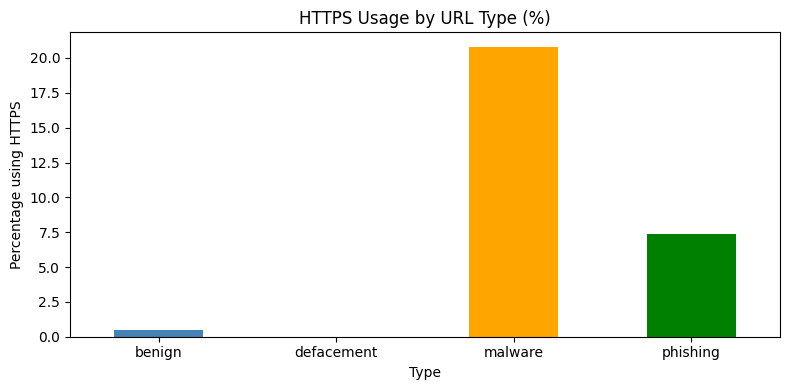


HTTPS usage percentage by type:
type
benign         0.47
defacement     0.00
malware       20.80
phishing       7.40
Name: has_https, dtype: float64


In [8]:
# Cell 7 — HTTPS Presence
df['has_https'] = df['url'].str.startswith('https').astype(int)

https_df = df.groupby('type')['has_https'].mean() * 100

plt.figure(figsize=(8,4))
https_df.plot(kind='bar', color=['steelblue','crimson','orange','green'])
plt.title('HTTPS Usage by URL Type (%)')
plt.ylabel('Percentage using HTTPS')
plt.xlabel('Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nHTTPS usage percentage by type:")
print(https_df.round(2))

## Top Level Domain (TLD) Analysis
We analyze the most common TLDs per URL type to identify patterns in domain usage.

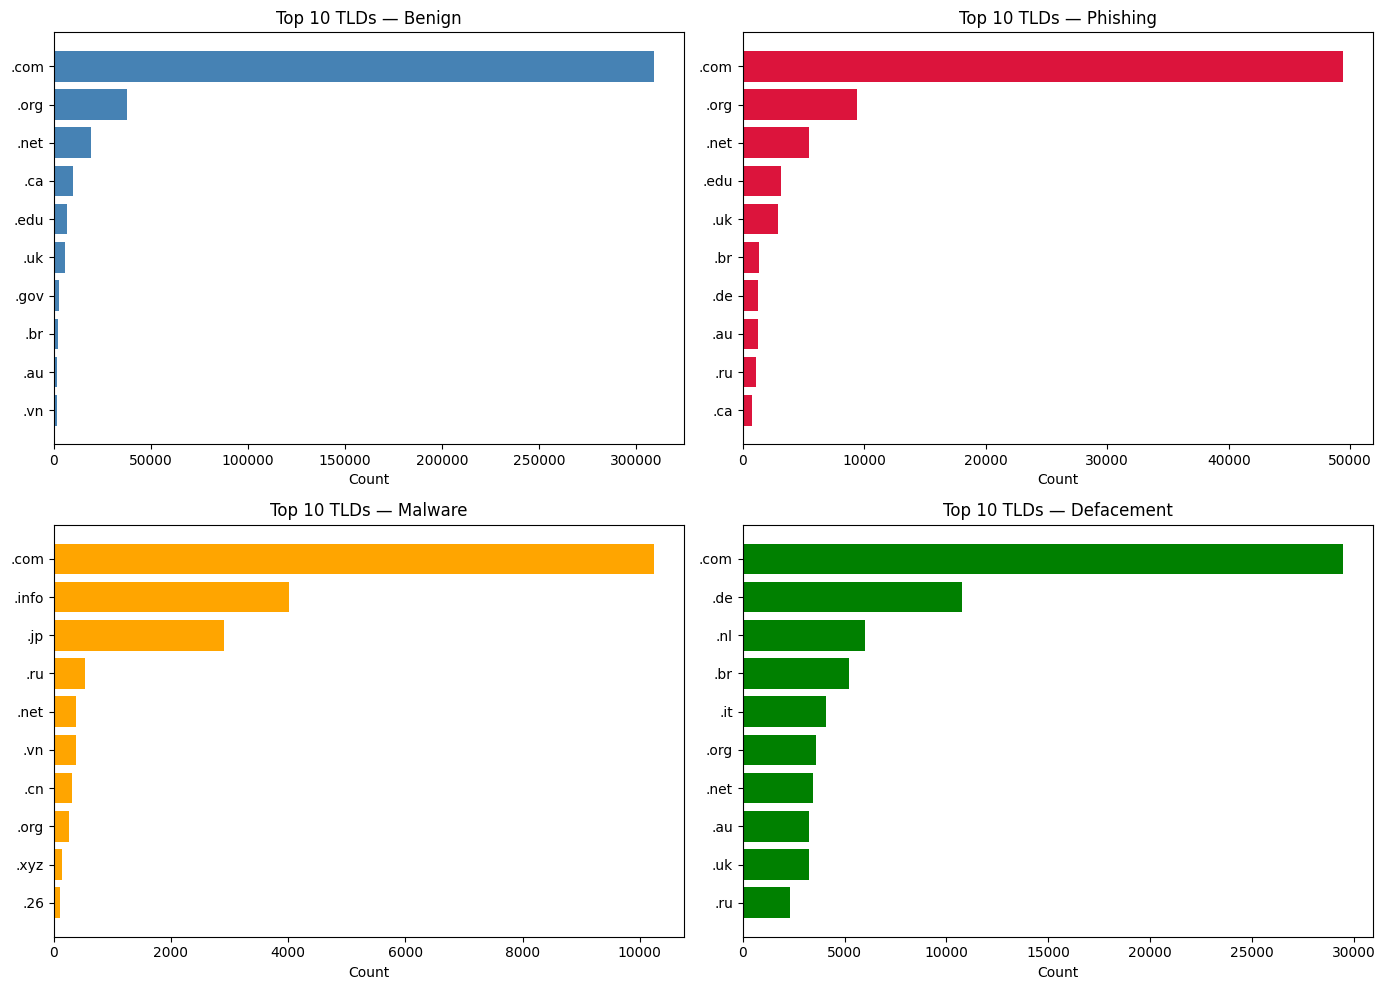

In [9]:
# Cell 8 — TLD Analysis
def extract_tld(url):
    try:
        domain = re.sub(r'https?://', '', url).split('/')[0]
        parts = domain.split('.')
        return '.' + parts[-1] if len(parts) > 1 else 'unknown'
    except:
        return 'unknown'

df['tld'] = df['url'].apply(extract_tld)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, t in zip(axes.flatten(), ['benign', 'phishing', 'malware', 'defacement']):
    top_tlds = df[df['type']==t]['tld'].value_counts().head(10)
    ax.barh(top_tlds.index[::-1], top_tlds.values[::-1], color='steelblue' if t=='benign' else 'crimson' if t=='phishing' else 'orange' if t=='malware' else 'green')
    ax.set_title(f'Top 10 TLDs — {t.capitalize()}')
    ax.set_xlabel('Count')

plt.tight_layout()
plt.show()

## Duplicate Check
We check for duplicate URLs in the dataset to ensure model training is not biased by repeated entries.

## Duplicate Check
We check for duplicate URLs in the dataset to ensure model training is not biased by repeated entries.

## Duplicate Check
We check for duplicate URLs in the dataset to ensure model training is not biased by repeated entries.

Total URLs:      651,191
Unique URLs:     641,119
Duplicate URLs:  10,072
Duplicate %:     1.55%


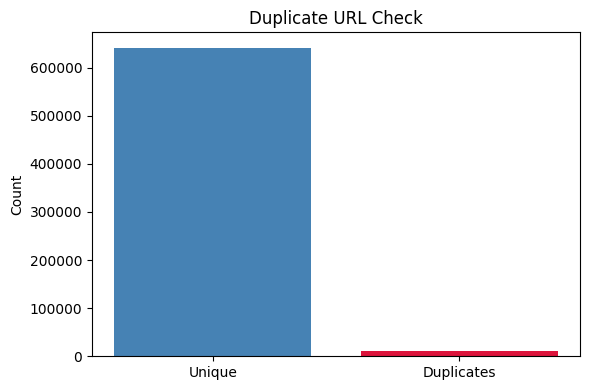

In [14]:
# Cell 9 — Duplicate Check
total = len(df)
duplicates = df.duplicated(subset=['url']).sum()
unique = total - duplicates

print(f"Total URLs:      {total:,}")
print(f"Unique URLs:     {unique:,}")
print(f"Duplicate URLs:  {duplicates:,}")
print(f"Duplicate %:     {duplicates/total*100:.2f}%")

# Plot
plt.figure(figsize=(6,4))
plt.bar(['Unique', 'Duplicates'], [unique, duplicates], color=['steelblue', 'crimson'])
plt.title('Duplicate URL Check')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## EDA Summary URL Dataset
Key findings from the exploratory data analysis:
- The dataset contains 651,191 URLs across 4 classes: benign (65%), defacement (15%), phishing (14%), and malware (5%)
- For binary classification, phishing/defacement/malware will be combined as malicious vs benign
- Phishing URLs are surprisingly shorter on average (45 chars) compared to benign (57 chars)
- Defacement URLs are the longest (86 chars) suggesting complex directory structures
- Suspicious keywords like "login", "verify", "account" appear more frequently in phishing URLs
- These findings justify the use of lexical string-based features for URL classification without requiring any network calls

Additional findings:
- Only 1.55% duplicate URLs found — dataset is largely unique and unbiased
- HTTPS presence is low across all types, confirming HTTPS alone is not a reliable safety indicator
- Phishing URLs occasionally use HTTPS (7.4%) to appear legitimate highlighting the need for multi-feature detection
- TLD patterns differ across types providing useful signal for classification
- These findings confirm that lexical features combined are more powerful than any single feature alone